<a href="https://colab.research.google.com/github/nandita1906/BigData-MNIST-Assignment/blob/main/MNIST_DataLoadAndProcess.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import get_file

In [2]:

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
path = get_file("mnist.npz", url)

data = np.load(path)

x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]

print("Dataset loaded successfully!")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!


In [3]:

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
print("Data type:", x_train.dtype)
print("Pixel range:", x_train.min(), "to", x_train.max())

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Data type: uint8
Pixel range: 0 to 255


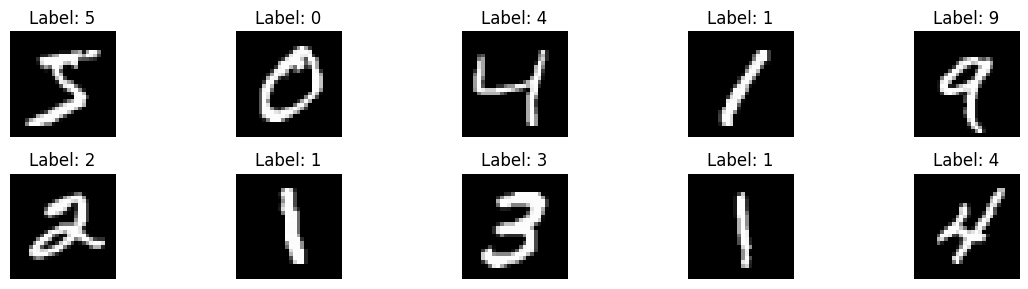

In [4]:

plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

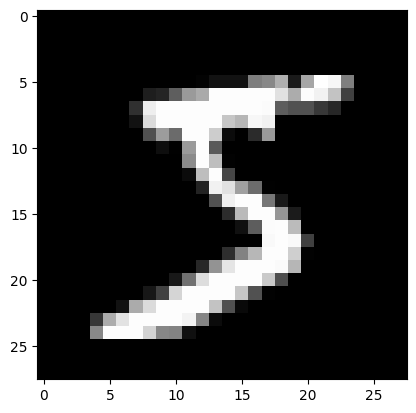

Label: 5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 2

In [5]:

plt.imshow(x_train[0], cmap="gray")
plt.show()

print("Label:", y_train[0])
print(x_train[0])

In [6]:

x_train_norm = x_train.astype("float32") / 255
x_test_norm = x_test.astype("float32") / 255

print("New pixel range:", x_train_norm.min(), "to", x_train_norm.max())
print("New data type:", x_train_norm.dtype)

New pixel range: 0.0 to 1.0
New data type: float32


In [7]:

import cv2

x_train_blur = np.array([
    cv2.GaussianBlur(img, (3, 3), 0) for img in x_train
])

x_test_blur = np.array([
    cv2.GaussianBlur(img, (3, 3), 0) for img in x_test
])

print("Blurred training data:", x_train_blur.shape)
print("Blurred testing data:", x_test_blur.shape)

Blurred training data: (60000, 28, 28)
Blurred testing data: (10000, 28, 28)


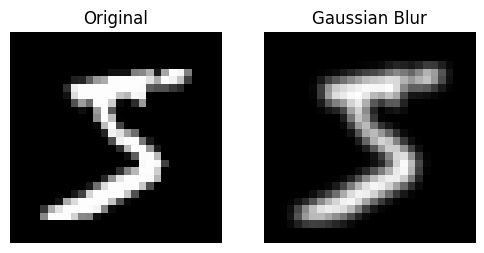

In [8]:

plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(x_train[0], cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(x_train_blur[0], cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.show()

In [9]:

print("Normalized range:", x_train_norm.min(), x_train_norm.max())
print("Blurred image shape:", x_train_blur.shape)
print("Labels unchanged:", np.array_equal(y_train, y_train))

Normalized range: 0.0 1.0
Blurred image shape: (60000, 28, 28)
Labels unchanged: True
